# Praktikum Machine Learning: Klasifikasi Pay Band

**Nama:** Daffa Aufa Afif

**NRP:** 5054251022

Template Kaggle Competition Praktikum Machine Learning (materi Klasifikasi).

Deepseek:
```bin
    https://chat.deepseek.com/share/7oub9ne0q5azxf60kt
    https://chat.deepseek.com/share/vs1il83n4xhpcdsawv
    https://chat.deepseek.com/share/tv6k0cqlrcs53d88ni
    https://chat.deepseek.com/share/v2hed86ozbkmbllkb9
```
maaf gak rapi mas/mbak

# Penjelasan singkat: 
Ide(dan 'promt' auto complete) ada diatas tiap kode. fitur yang digunakan terdiri dari beberapa fitur numerik dan kategorikal:
``` py
    NUM_COLS = [
        "years_experience",
        "tenure_years",
        "performance_review_score",
        "salary_annual_local",
    ]
    CAT_COLS = [
        "source_dataset",
        "import_batch",
        "education_level",
        "department",
        "job_title",
        "country",
        "performance_rating",
        "currency",
        "remote_status" # baru ditambahkan karena baru kepikiran
    ]
```
Fitur lain seperti `age`, `etnicity`, dan `gender` tidak dimasukkan karena ini sudah abad 21, masa iya gaji lihat fitur seperti itu.        `source_dataset` dan `import_batch` dua fitur ini dipakai karena siapa tau ada pattern tersembunyi, dan juga fitur ini yang paling bersih.

Kenapa pakai ensemble learning? sekalian belajar buat datmin(moga gak seaneh ini datasetnya). yang dicoba adalah `HistGradientBoostingClassifier` dan `ExtraTreesClassifier`. Lalu pakai soft vote biar gak *tie*.

mohon maaf kalau notebook kurang bersih/rapi, karena ditengah pengerjaan saya melakukan restart laptop dan ternyata notebook belum tersave, jadi ada beberapa kolom yang hilang.

## Setup

In [1]:
# Import Library
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier,VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
# tambahan library yang mungkin diperlukan
#
#

## Load Data

In [2]:
# Sesuaikan path dengan lokasi file kalian (Kaggle: /kaggle/input/<nama-kompetisi>/...)
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

print(df_train.shape, df_test.shape)
df_train.head()

(60430, 21) (29070, 20)


,employee_id,source_dataset,import_batch,age,gender,ethnicity,education_level,years_experience,tenure_years,department,...,country,remote_status,performance_rating,performance_review_score,hire_date,currency,salary_raw,record_hash,notes,pay_band
0,EMP-194754,hris_export_2023,24,NaN,?,NaN,bachelor's degree,NaN,6.0,Engineering,...,PH,Hybrid,exceeds,3.1,04-30-2020,PHP,"191,210 per month",fedab652e9c8,NaN,Band 2
1,EMP-109967,hris_export_2023,22,0.0,female,White,Associate Degree,24.0,0.0,IT,...,Brazil,On site,Meets Expectations,4.1,02 Apr 2026,BRL,"BRL 250,722",a94720bee9e0,NaN,Band 2
2,EMP-128419,hris_export_2023,8,33.0,FEMALE,unknown,PhD,12.0,1.0,Legal,...,United Kingdom,Remote,Meets Expectations,2.1,23 Dec 2024,?,"28,276.28",8f8b484b87ee,NaN,Band 1
3,EMP-108690,hris_export_2023,39,NaN,Woman,Asian,PhD,20.0,4.0,Legal,...,Brazil,On-site,Meets Expectations,4.1,2022-07-20,BRL,18315 monthly,a7a6d7f3cc91,NaN,Band 1
4,EMP-169742,acquired_company_legacy,22,39.0,Other,White,bachelor's degree,-1.0,4.0,Data Science Department,...,USA,Hybrid,NaN,3.5,"March 31, 2022",USD,"20.855,27 USD",7826c5135f34,NaN,Band 1


## Exploratory Data Analysis

Lengkapi bagian ini sesuai dengan **EDA** yang kalian lakukan.

In [3]:
for _i, i in enumerate([df_train,df_test]):  
    print(_i,end="\n\n")  
    print(i.info())
    print(i.describe().T)
    print(i.isna().sum())
    print()    

0

<class 'pandas.DataFrame'>
RangeIndex: 60430 entries, 0 to 60429
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   employee_id               60430 non-null  str    
 1   source_dataset            60430 non-null  str    
 2   import_batch              60430 non-null  int64  
 3   age                       40919 non-null  float64
 4   gender                    59078 non-null  str    
 5   ethnicity                 49033 non-null  str    
 6   education_level           58188 non-null  str    
 7   years_experience          38853 non-null  float64
 8   tenure_years              59842 non-null  float64
 9   department                60430 non-null  str    
 10  job_title                 59229 non-null  str    
 11  country                   60430 non-null  str    
 12  remote_status             55467 non-null  str    
 13  performance_rating        58143 non-null  str    
 14  performance_re

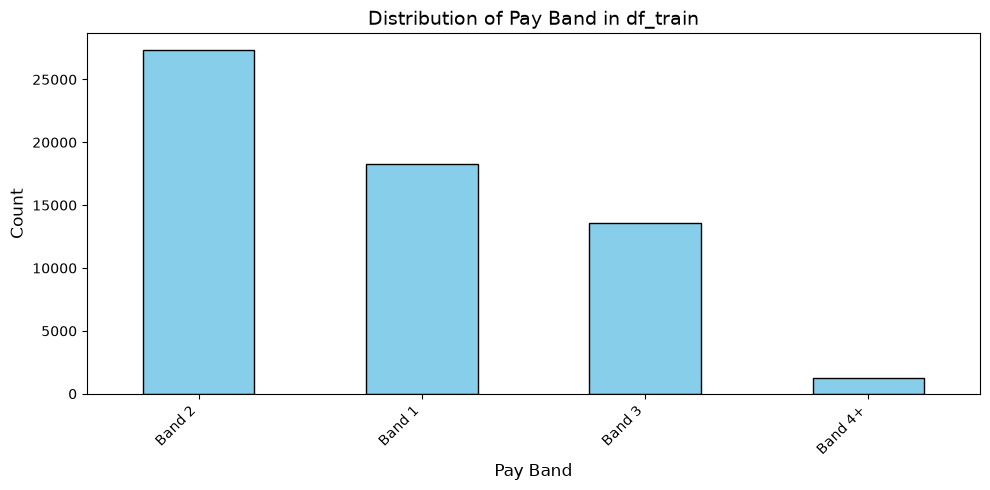

In [4]:
# Set up the figure size
plt.figure(figsize=(10, 5))

# Plot value counts as a bar chart
df_train['pay_band'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')

# Format the plot
plt.title('Distribution of Pay Band in df_train', fontsize=14)
plt.xlabel('Pay Band', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Display the plot
plt.show()

### Fokus pada fitur ['source_dataset', 'import_batch', 'education_level', 'years_experience', 'tenure_years', 'departement', 'job_title', 'country', 'performance_rating', 'performance_review_score', 'salary_raw', 'currency']

In [5]:
FOCUS = ['pay_band','source_dataset', 'import_batch', 'education_level', 'years_experience', 'tenure_years', 
         'department', 'job_title', 'country', 'performance_rating', 'performance_review_score', 'salary_raw', 
         'currency', 'remote_status']
df_foc = df_train[FOCUS].copy()
print(df_foc.info())
print(df_train[FOCUS].info())

<class 'pandas.DataFrame'>
RangeIndex: 60430 entries, 0 to 60429
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pay_band                  60430 non-null  str    
 1   source_dataset            60430 non-null  str    
 2   import_batch              60430 non-null  int64  
 3   education_level           58188 non-null  str    
 4   years_experience          38853 non-null  float64
 5   tenure_years              59842 non-null  float64
 6   department                60430 non-null  str    
 7   job_title                 59229 non-null  str    
 8   country                   60430 non-null  str    
 9   performance_rating        58143 non-null  str    
 10  performance_review_score  50784 non-null  float64
 11  salary_raw                60430 non-null  str    
 12  currency                  54911 non-null  str    
 13  remote_status             55467 non-null  str    
dtypes: float64(3), in

In [6]:
for i in FOCUS:
    if i == 'pay_band': continue
    print(df_test[i].value_counts())

source_dataset
hris_export_2023           14659
survey_response_2024       10125
acquired_company_legacy     4286
Name: count, dtype: int64
import_batch
23    804
33    800
1     785
15    784
2     782
3     780
19    776
26    774
27    770
32    764
34    764
7     763
14    761
16    761
20    758
4     754
21    754
37    749
38    744
28    744
10    743
17    741
25    739
31    737
39    736
8     735
9     734
24    731
12    731
30    727
29    723
22    722
13    711
18    711
6     703
5     701
36    700
11    694
35    680
Name: count, dtype: int64
education_level
High School          2866
PhD                  2840
Master's             2797
bachelor's degree    2791
Bachelors            2774
Bachelor's           2767
MSc                  2744
BSc                  2734
PhD.                 2675
Associate Degree     2655
?                     120
-                     117
unknown               114
Name: count, dtype: int64
years_experience
-1          2016
999          846


In [7]:
for i in df_foc.columns:
    print(df_foc[i].value_counts())

pay_band
Band 2     27320
Band 1     18278
Band 3     13583
Band 4+     1249
Name: count, dtype: int64
source_dataset
hris_export_2023           30303
survey_response_2024       20880
acquired_company_legacy     9247
Name: count, dtype: int64
import_batch
37    1626
18    1620
15    1609
9     1596
29    1589
3     1582
2     1579
4     1579
20    1574
6     1569
34    1566
31    1565
17    1562
10    1561
12    1560
32    1558
19    1557
28    1556
39    1554
8     1550
33    1550
27    1549
22    1543
30    1541
7     1540
36    1536
38    1533
5     1532
35    1528
11    1528
16    1523
1     1518
21    1517
13    1515
14    1507
23    1496
24    1493
26    1493
25    1476
Name: count, dtype: int64
education_level
bachelor's degree    5847
PhD                  5831
PhD.                 5826
MSc                  5814
Master's             5776
BSc                  5753
Associate Degree     5737
High School          5678
Bachelors            5613
Bachelor's           5612
?            

## Preprocessing

Lengkapi bagian ini sesuai dengan **Preprocessing Data** yang kalian lakukan.

In [8]:
print(df_foc.duplicated().sum())
df_foc = df_foc.drop_duplicates()
print(df_foc.duplicated().sum())

841
0


In [9]:
# Normalize education labels and keep unknown values missing until feature preparation.
def clean_education(series):
    cleaned = (
        series.astype("string")
        .str.lower()
        .str.strip()
        .str.replace(r"[^\w\s]", "", regex=True)
    )

    cleaned = cleaned.replace({"": pd.NA, "unknown": pd.NA})

    for initial in ["b", "m", "a", "h", "p"]:
        cleaned = cleaned.replace(
            rf"^{initial}.*",
            initial,
            regex=True,
        )

    return cleaned

df_foc["education_level"] = clean_education(df_foc["education_level"])
df_test["education_level"] = clean_education(df_test["education_level"])

print(df_foc["education_level"].value_counts(dropna=False))
print(df_test["education_level"].value_counts(dropna=False))

education_level
b       22501
p       11493
m       11428
a        5663
h        5596
<NA>     2908
Name: count, dtype: Int64
education_level
b       11066
m        5541
p        5515
h        2866
a        2655
<NA>     1427
Name: count, dtype: Int64


In [10]:
#	year_experience if lower than 0 or na, give val=0. if higher than 60 then val = median
df_foc['years_experience'] = df_foc['years_experience'].apply(lambda x: np.nan if x < 0 or pd.isna(x) else x)
df_foc['years_experience'] = df_foc['years_experience'].apply(lambda x: np.nan if x > 60 else x)
print(df_foc['years_experience'].describe())
# if test data has 'month' in it, the value will be converted to years by dividing by 12.
def convert_month_to_year(x):
    if 'month' in str(x):
        # delete the month word and convert to float
        x = str(x).replace('month','').strip()
        # remove all words that are not numbers or decimal points
        x = ''.join(c for c in x if c.isdigit() or c == '.')
        x = float(x)
        return x/12
    elif 'y' in str(x):
        # remove all words that are not numbers or decimal points
        x = ''.join(c for c in x if c.isdigit() or c == '.')
        x = float(x)
        return x
    else:
        return float(x)
df_test['years_experience'] = df_test['years_experience'].apply(convert_month_to_year)
df_test['years_experience'] = df_test['years_experience'].apply(lambda x:  np.nan  if isinstance(x, (int, float)) and x < 0 or pd.isna(x) else x)
df_test['years_experience'] = df_test['years_experience'].apply(lambda x:  np.nan  if isinstance(x, (int, float)) and x > 60 else x)
print(df_test['years_experience'].describe()) 

count    33015.000000
mean        15.122429
std          8.675101
min          0.000000
25%          9.000000
50%         15.000000
75%         21.000000
max         40.000000
Name: years_experience, dtype: float64
count    25915.000000
mean        14.697858
std          8.691496
min          0.000000
25%          8.000000
50%         14.000000
75%         21.000000
max         40.000000
Name: years_experience, dtype: float64


In [11]:
# tenure_years if lower than 0 or na, give val=0. if higher than 60 then val = mean
df_foc['tenure_years'] = df_foc['tenure_years'].apply(lambda x:  np.nan  if x < 0 or pd.isna(x) else x)
df_foc['tenure_years'] = df_foc['tenure_years'].apply(lambda x:  np.nan  if x > 60 else x)
print(df_foc['tenure_years'].describe())
df_test['tenure_years'] = df_test['tenure_years'].apply(lambda x:  np.nan  if x < 0 or pd.isna(x) else x)
df_test['tenure_years'] = df_test['tenure_years'].apply(lambda x:  np.nan  if x > 60 else x)
print(df_test['tenure_years'].describe())

count    57752.000000
mean         2.950374
std          2.529745
min          0.000000
25%          1.000000
50%          3.000000
75%          5.000000
max         16.000000
Name: tenure_years, dtype: float64
count    28118.000000
mean         2.910449
std          2.555696
min          0.000000
25%          1.000000
50%          3.000000
75%          5.000000
max         14.000000
Name: tenure_years, dtype: float64


In [12]:
#department replace all with lower case, remove anything that is not a word such as [.`'] and spaces. 
df_foc['department'] = df_foc['department'].str.lower().str.strip().str.replace(r"[^\w\s]", "", regex=True)
# If the cleaned ends up "" or just spaces or Na then replace the val with "unknown"
df_foc['department'] = df_foc['department'].apply(lambda x:  np.nan  if x == "" or pd.isna(x) else x)
#print unique values
print(df_foc['department'].unique())

#department replace all with lower case, remove anything that is not a word such as [.`'] and spaces. 
df_test['department'] = df_test['department'].str.lower().str.strip().str.replace(r"[^\w\s]", "", regex=True)
# If the cleaned ends up "" or just spaces or Na then replace the val with "unknown"
df_test['department'] = df_test['department'].apply(lambda x:  np.nan  if x == "" or pd.isna(x) else x)
#print unique values
print(df_test['department'].unique())

# remove all ['dept','department','team','of'] from the department column
words_to_kill = ['dept','department','team','of']
pattern = r'\b(?:' + '|'.join(words_to_kill) + r')\b'
df_foc['department'] = (
    df_foc['department']
    .astype(str) 
    .str.replace(pattern, '', case=False, regex=True)
    .str.replace(r'\s+', ' ', regex=True)  
    .str.strip()  
)
df_test['department'] = (
    df_test['department']
    .astype(str) 
    .str.replace(pattern, '', case=False, regex=True)
    .str.replace(r'\s+', ' ', regex=True)  
    .str.strip()  
)
# handle empty or na strings after cleaning
df_foc['department'] = df_foc['department'].apply(lambda x:  np.nan  if x == "" or pd.isna(x) else x)
df_test['department'] = df_test['department'].apply(lambda x:  np.nan  if x == "" or pd.isna(x) else x)
print()
print(df_foc['department'].unique())
print(df_test['department'].unique())

<StringArray>
[                'engineering',                          'it',
                       'legal',     'data science department',
            'legal department',                       'sales',
                  'operations',                          'hr',
            'customer support',                      'design',
       'operations department',           'data science dept',
                   'marketing',             'operations team',
                'data science',      'engineering department',
                'product dept',                     'finance',
                     'hr team',                     'product',
 'customer support department',                  'legal dept',
       'customer support dept',             'operations dept',
              'marketing team',           'design department',
                'finance team',            'sales department',
               'hr department',                 'design team',
            'engineering dept',          

In [13]:
print(df_foc['job_title'].unique())
print(df_test['job_title'].unique())
# job_title replace all with lower case, remove anything that is not a word such as [.`'] and spaces. 
df_foc['job_title'] = df_foc['job_title'].str.lower().str.strip().str.replace(r"[^\w\s]", "", regex=True)
df_test['job_title'] = df_test['job_title'].str.lower().str.strip().str.replace(r"[^\w\s]", "", regex=True)
# If the cleaned ends up "" or just spaces or Na then replace the val with "unknown"
df_foc['job_title'] = df_foc['job_title'].apply(lambda x:  np.nan  if x == "" or pd.isna(x) else x)
df_test['job_title'] = df_test['job_title'].apply(lambda x:  np.nan  if x == "" or pd.isna(x) else x)

# mapping words
WORD_FIXES = {
    "sr": "senior",
    "vp": "vice president",
    "mgr": "manager",
    "manger": "manager",
    "eng": "engineer",
    "enginer": "engineer",
    "anlst": "analyst",
    "analist": "analyst",
    "scientst": "scientist",
    "spec": "specialist",
    "coord": "coordinator",
    "admin": "administrator",
    "rep": "representative",
    "councel": "counsel",
    "exectuive": "executive",
}

# Clean one job title using the same rules for training and test data.
def clean_job_title(value):
    if pd.isna(value) or str(value).strip().lower() in {"", "?", "unknown"}:
        return  np.nan 
    text = str(value).strip().lower()
    text = re.sub(r"[^a-z0-9]+", " ", text)
    words = [WORD_FIXES.get(word, word) for word in text.split()]
    return " ".join(words) or  np.nan 


df_foc["job_title"] = df_foc["job_title"].map(clean_job_title)
df_test["job_title"] = df_test["job_title"].map(clean_job_title)


#print unique values
print(df_foc['job_title'].unique())
print(df_test['job_title'].unique())


<StringArray>
[               'STAFF ENG.',     'IT SUPPORT SPECIALIST',
                 'Paralegal',                 'paralegal',
                'ML Enginer',           'General Counsel',
             'sales manager',        'Operations Manager',
                       'COO',                'HR Manager',
 ...
      '  MARKETING Manger  ',         'operations  anlst',
 '  VICE PRESIDENT PEOPLE  ',       '  financial anlst  ',
             'DATA  ANALIST',     'LOGISTICS  CORDINATOR',
     '  marketing manager  ',           '  ml engineer  ',
       '  SR. PRODUCT MGR  ',      'software  enginer  i']
Length: 874, dtype: str
<StringArray>
[            'Data  Anlst',                     'CFO',
          'FINANCE MANGER', 'Senior  Data  Scientist',
              'ML Enginer',   'Sales Development Rep',
           'Systems Admin',         'PRODUCT MANAGER',
            'head of data',     'HR Business Partner',
 ...
          '  accountant  ',       '  SYSTEMS ADMIN  ',
        'Product  

In [14]:
print(df_foc['country'].unique())
print(df_test['country'].unique())
COUNTRY_MAP = {
    # Philippines
    'ph': 'PH', 'philippines': 'PH', 'phillipines': 'PH', 'philipines': 'PH',
    # Brazil
    'br': 'BR', 'brazil': 'BR', 'brasil': 'BR',
    # United Kingdom
    'uk': 'GB', 'gb': 'GB', 'united kingdom': 'GB', 'great britain': 'GB',
    'england': 'GB', 'britain': 'GB',
    # United States
    'us': 'US', 'usa': 'US', 'united states': 'US', 'united states of america': 'US',
    'america': 'US',
    # France
    'fr': 'FR', 'france': 'FR',
    # Kenya
    'ke': 'KE', 'kenya': 'KE',
    # Canada
    'ca': 'CA', 'canada': 'CA',
    # South Africa
    'za': 'ZA', 'south africa': 'ZA', 's africa': 'ZA', 'sa': 'ZA',
    # Netherlands
    'nl': 'NL', 'netherlands': 'NL', 'holland': 'NL', 'the netherlands': 'NL',
    # Nigeria
    'ng': 'NG', 'nigeria': 'NG',
    # Singapore
    'sg': 'SG', 'singapore': 'SG',
    # Australia
    'au': 'AU', 'australia': 'AU', 'aus': 'AU',
    # Germany
    'de': 'DE', 'germany': 'DE', 'deutschland': 'DE',
    # India
    'in': 'IN', 'india': 'IN', 'bharat': 'IN',
}


def clean_country(series: pd.Series) -> pd.Series:
    """Normalize a column of country names to ISO-2 codes."""
    cleaned = (
        series.astype(str)
              .str.lower()
              .str.strip()
              .str.replace(r"[^\w\s]", "", regex=True)   # drop . ' , etc.
              .str.replace(r"\s+", " ", regex=True)       # collapse spaces
    )
    return cleaned.map(COUNTRY_MAP)


# Apply to both dataframes
df_foc['country'] = clean_country(df_foc['country'])
df_test['country'] = clean_country(df_test['country'])

# print(df_foc['country'].unique())
print(df_foc['country'].unique())
print(df_test['country'].unique())

<StringArray>
[            'PH',         'Brazil', 'United Kingdom',            'USA',
         'France',          'Kenya',             'US',  'United States',
         'Canada',             'UK',   'South Africa',    'Netherlands',
        'Nigeria',      'Singapore',      'Australia',        'Germany',
    'Philippines',          'India',             'AU',             'ZA',
         'Brasil',             'BR',             'NG',             'KE',
             'NL',    'Phillipines',             'CA',      'S. Africa',
             'IN',             'DE',             'SG',             'FR',
         'Bharat',            'Aus',        'Holland',    'Deutschland']
Length: 36, dtype: str
<StringArray>
[            'UK',    'Netherlands',    'Philippines',        'Holland',
      'Singapore',        'Nigeria',      'Australia',   'South Africa',
 'United Kingdom',        'Germany',          'Kenya',             'US',
            'Aus',         'France',  'United States',         'Canada',


In [15]:
print(df_foc['performance_rating'].unique())
print(df_test['performance_rating'].unique())
# performance_rating replace all with lower case, remove anything that is not a word such as [.`'] and spaces. 
df_foc['performance_rating'] = df_foc['performance_rating'].str.lower().str.strip().str.replace(r"[^\w\s]", "", regex=True)
df_test['performance_rating'] = df_test['performance_rating'].str.lower().str.strip().str.replace(r"[^\w\s]", "", regex=True)
# If the cleaned ends up "" or just spaces or Na then replace the val with "unknown". 
df_foc['performance_rating'] = df_foc['performance_rating'].apply(lambda x:  np.nan  if x == "" or pd.isna(x) else x)
df_test['performance_rating'] = df_test['performance_rating'].apply(lambda x:  np.nan  if x == "" or pd.isna(x) else x)
# if start with m then val = 'me', if start with e then val = 'ee', if start with b then val = 'be'
def map_performance_rating(x):
    if pd.isna(x):
        return np.nan
    if x.startswith('m'):
        return 'me'
    elif x.startswith('e'):
        return 'ee'
    elif x.startswith('b'):
        return 'be'
    else:
        return x
df_foc['performance_rating'] = df_foc['performance_rating'].apply(map_performance_rating)
df_test['performance_rating'] = df_test['performance_rating'].apply(map_performance_rating)

print(df_foc['performance_rating'].unique())
print(df_test['performance_rating'].unique())

<StringArray>
[             'exceeds',   'Meets Expectations',                    nan,
 'Exceeds Expectations',   'Below Expectations',                'meets',
              'unknown',                    '?',                    '-']
Length: 9, dtype: str
<StringArray>
[  'Meets Expectations', 'Exceeds Expectations',              'exceeds',
   'Below Expectations',                'meets',                    nan,
                    '?',                    '-',              'unknown']
Length: 9, dtype: str
<StringArray>
['ee', 'me', nan, 'be', 'unknown']
Length: 5, dtype: str
<StringArray>
['me', 'ee', 'be', nan, 'unknown']
Length: 5, dtype: str


In [16]:
print(df_foc['performance_review_score'].describe())
print(df_test['performance_review_score'].describe())
# performance_review_score if below 1 then set to 1, 
df_foc['performance_review_score'] = df_foc['performance_review_score'].apply(lambda x:  np.nan  if x < 1 else x)
df_test['performance_review_score'] = df_test['performance_review_score'].apply(lambda x:  np.nan  if x < 1  else x)
# if higher than 20 then val divide by 20, 
df_foc['performance_review_score'] = df_foc['performance_review_score'].apply(lambda x: x/20 if x >= 20 else x)
df_test['performance_review_score'] = df_test['performance_review_score'].apply(lambda x: x/20 if x >= 20 else x)
# if higher than 5 or na then set to mean
df_foc['performance_review_score'] = df_foc['performance_review_score'].apply(lambda x:  np.nan  if x > 5 or pd.isna(x) else x)
df_test['performance_review_score'] = df_test['performance_review_score'].apply(lambda x:  np.nan if x > 5 or pd.isna(x) else x)
print(df_foc['performance_review_score'].describe())
print(df_test['performance_review_score'].describe())

count    50081.000000
mean         8.542775
std         18.143056
min          1.000000
25%          2.900000
50%          3.500000
75%          4.200000
max        100.000000
Name: performance_review_score, dtype: float64
count    24652.000000
mean         9.639080
std         19.819608
min          1.000000
25%          2.900000
50%          3.500000
75%          4.300000
max        100.000000
Name: performance_review_score, dtype: float64
count    50081.000000
mean         3.405517
std          0.845775
min          1.000000
25%          2.800000
50%          3.400000
75%          4.000000
max          5.000000
Name: performance_review_score, dtype: float64
count    24652.000000
mean         3.383847
std          0.871509
min          1.000000
25%          2.800000
50%          3.400000
75%          4.000000
max          5.000000
Name: performance_review_score, dtype: float64


In [17]:
VALID_CURRENCIES = {
    "USD", "EUR", "GBP", "INR", "AUD", "ZAR",
    "NGN", "KES", "CAD", "BRL", "PHP", "SGD",
}

# Convert mixed thousands and decimal separators into a float.
def parse_amount(number_text):
    number_text = number_text.rstrip(",.")

    # Use the last separator as the decimal mark when both types appear.
    if "," in number_text and "." in number_text:
        decimal = "," if number_text.rfind(",") > number_text.rfind(".") else "."
        thousands = "." if decimal == "," else ","
        number_text = number_text.replace(thousands, "").replace(decimal, ".")

    # Handle numbers containing only commas or only periods.
    elif "," in number_text or "." in number_text:
        separator = "," if "," in number_text else "."
        groups = number_text.split(separator)

        # A final group of three digits indicates thousands.
        if len(groups[-1]) == 3 and all(len(g) == 3 for g in groups[1:]):
            number_text = "".join(groups)
        else:
            number_text = "".join(groups[:-1]) + "." + groups[-1]

    return float(number_text)


# Extract yearly salary and any unambiguous currency written in salary_raw.
def parse_salary(raw):
    text = "" if pd.isna(raw) else str(raw).strip()

    codes = [
        token
        for token in re.findall(r"\b[A-Z]{3}\b", text.upper())
        if token in VALID_CURRENCIES
    ]

    symbol_map = {
            '$': 'USD', '€': 'EUR', '£': 'GBP', '₹': 'INR',
            '¥': 'JPY', '₩': 'KRW', 'a$': 'AUD', 'c$': 'CAD',
            's$': 'SGD', 'hk$': 'HKD'
        }

    unique_codes = set(codes)

    if len(unique_codes) == 1:
        currency_in_salary = next(iter(unique_codes))
    elif len(unique_codes) > 1:
        currency_in_salary = pd.NA
    else:
        remaining = text.lower()
        currencies_found = set()

        for symbol, currency in symbol_map.items():
            if symbol in remaining:
                currencies_found.add(currency)
                remaining = remaining.replace(symbol, "")

        currency_in_salary = (
            next(iter(currencies_found))
            if len(currencies_found) == 1
            else pd.NA
        )

    lower = text.lower()

    if "month" in lower or re.search(r"/\s*mo\b", lower):
        period, factor = "month", 12
    elif "week" in lower:
        period, factor = "week", 52
    elif "hour" in lower:
        period, factor = "hour", 2080
    else:
        period, factor = "year", 1

    match = re.search(r"(\d[\d,.]*)(?:\s*(k)\b)?", text, flags=re.I)

    if match is None:
        annual_salary = np.nan
    else:
        amount = parse_amount(match.group(1))

        if match.group(2):
            amount *= 1000

        annual_salary = amount * factor

    return annual_salary, period, currency_in_salary


# Apply the same salary transformation to train and test.
def add_salary_features(frame):
    parsed = pd.DataFrame(
        [parse_salary(raw) for raw in frame["salary_raw"]],
        columns=["salary_annual_local", "salary_period", "currency_in_salary"],
        index=frame.index,
    )

    # Store salary as a numeric yearly amount.
    frame["salary_annual_local"] = pd.to_numeric(
        parsed["salary_annual_local"], errors="coerce"
    )
    frame["salary_period"] = parsed["salary_period"]
    frame["currency_in_salary"] = parsed["currency_in_salary"].astype("string")

    # Normalize the existing dataset currency column.
    dataset_currency = frame["currency"].astype("string").str.strip().str.upper()
    dataset_currency = dataset_currency.where(
        dataset_currency.isin(VALID_CURRENCIES), pd.NA
    )

    # Flag disagreements while keeping the dataset currency unchanged.
    frame["currency_mismatch"] = (
        dataset_currency.notna()
        & frame["currency_in_salary"].notna()
        & dataset_currency.ne(frame["currency_in_salary"])
    ).fillna(False).astype(bool)

    # Fill only missing dataset currencies from salary_raw.
    frame["currency"] = dataset_currency.fillna(frame["currency_in_salary"])

    return frame


# Update the two DataFrames already used in your notebook.
df_foc = add_salary_features(df_foc)
df_test = add_salary_features(df_test)

# Inspect the numeric salary, final currency, and any disagreements.
print(
    df_foc[
        ["salary_raw", "salary_annual_local", "currency",
         "currency_in_salary", "currency_mismatch"]
    ].head()
)
print("Train mismatches:", df_foc["currency_mismatch"].sum())
print("Test mismatches:", df_test["currency_mismatch"].sum())


          salary_raw  salary_annual_local currency currency_in_salary  \
0  191,210 per month           2294520.00      PHP               <NA>   
1        BRL 250,722            250722.00      BRL                BRL   
2          28,276.28             28276.28     <NA>               <NA>   
3      18315 monthly            219780.00      BRL               <NA>   
4      20.855,27 USD             20855.27      USD                USD   

   currency_mismatch  
0              False  
1              False  
2              False  
3              False  
4              False  
Train mismatches: 0
Test mismatches: 0


In [18]:
def clean_remote_status(df):
    s = df['remote_status'].astype(str).str.strip().str.lower()
    
    # Map variants to canonical form
    mapping = {
        'on-site': 'onsite',
        'onsite': 'onsite',
        'on site': 'onsite',
        'hybrid': 'hybrid',
        'remote': 'remote',
    }
    
    s = s.map(mapping)  # anything not in mapping -> NaN
    
    df['remote_status'] = s
    return df

df_foc = clean_remote_status(df_foc)
df_test = clean_remote_status(df_test)

# ------------------------------------------------------------
# Validate
# ------------------------------------------------------------
print("df_foc remote_status value counts:")
print(df_foc['remote_status'].value_counts(dropna=False))
print("\ndf_foc NaN count:", df_foc['remote_status'].isna().sum())

print("\ndf_test remote_status value counts:")
print(df_test['remote_status'].value_counts(dropna=False))
print("\ndf_test NaN count:", df_test['remote_status'].isna().sum())

df_foc remote_status value counts:
remote_status
remote    19944
onsite    19868
hybrid    13186
NaN        6591
Name: count, dtype: int64

df_foc NaN count: 6591

df_test remote_status value counts:
remote_status
onsite    9751
remote    9602
hybrid    6420
NaN       3297
Name: count, dtype: int64

df_test NaN count: 3297


In [19]:
# Drop exceed cols
df_foc = df_foc.drop(columns=['currency_in_salary','currency_mismatch','salary_raw','salary_period'])
FOCUS.remove('salary_raw')
FOCUS.append('salary_annual_local')

In [20]:
print(df_foc['currency'].unique())
print(df_test['currency'].unique())
for df in [df_foc, df_test]:
    df['currency'] = df['currency'].replace('<NA>',  np.nan )
print(df_foc['currency'].unique())
print(df_test['currency'].unique())

<StringArray>
['PHP', 'BRL',  <NA>, 'USD', 'EUR', 'KES', 'CAD', 'GBP', 'ZAR', 'NGN', 'SGD',
 'AUD', 'INR']
Length: 13, dtype: string
<StringArray>
['GBP', 'EUR', 'PHP', 'SGD', 'NGN', 'AUD', 'ZAR', 'KES',  <NA>, 'USD', 'CAD',
 'BRL', 'INR']
Length: 13, dtype: string
<StringArray>
['PHP', 'BRL',  <NA>, 'USD', 'EUR', 'KES', 'CAD', 'GBP', 'ZAR', 'NGN', 'SGD',
 'AUD', 'INR']
Length: 13, dtype: string
<StringArray>
['GBP', 'EUR', 'PHP', 'SGD', 'NGN', 'AUD', 'ZAR', 'KES',  <NA>, 'USD', 'CAD',
 'BRL', 'INR']
Length: 13, dtype: string


In [21]:
print(FOCUS)
print("Train")
print(df_foc.head())
print(df_foc.info())
print(df_foc.describe())
print("\n\n")
test_foc = [i for i in FOCUS if i !='pay_band']
print("Test")
print(df_test[test_foc].head())
print(df_test[test_foc].info())
print(df_test.describe())

print(df_foc.isna().sum())
print(df_test[test_foc].isna().sum())


['pay_band', 'source_dataset', 'import_batch', 'education_level', 'years_experience', 'tenure_years', 'department', 'job_title', 'country', 'performance_rating', 'performance_review_score', 'currency', 'remote_status', 'salary_annual_local']
Train
  pay_band           source_dataset  import_batch education_level  \
0   Band 2         hris_export_2023            24               b   
1   Band 2         hris_export_2023            22               a   
2   Band 1         hris_export_2023             8               p   
3   Band 1         hris_export_2023            39               p   
4   Band 1  acquired_company_legacy            22               b   

   years_experience  tenure_years    department              job_title  \
0               NaN           6.0   engineering         staff engineer   
1              24.0           0.0            it  it support specialist   
2              12.0           1.0         legal              paralegal   
3              20.0           4.0        

In [22]:
# Select the model features and create a stratified validation split.
NUM_COLS = [
    "years_experience",
    "tenure_years",
    "performance_review_score",
    "salary_annual_local",
]

CAT_COLS = [
    "source_dataset",
    "import_batch",
    "education_level",
    "department",
    "job_title",
    "country",
    "performance_rating",
    "currency",
    "remote_status"
]

FEATURES = NUM_COLS + CAT_COLS

def prepare_features(frame):
    result = frame[FEATURES].copy()

    for col in NUM_COLS:
        result[col] = pd.to_numeric(result[col], errors="coerce")

    for col in CAT_COLS:
        result[col] = result[col].fillna("__missing__").astype(str)

    return result

X = prepare_features(df_foc)
y = df_foc["pay_band"].copy()
X_test = prepare_features(df_test)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)
# Check training and test
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (47671, 13)
Validation: (11918, 13)
Test: (29070, 13)


In [23]:
# prepare for ensemble
# use ColumnTransformer for HistGradientBoostingClassifier
hgb_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM_COLS),
    (
        "cat",
        OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1,
            max_categories=100,
        ),
        CAT_COLS,
    ),
])

categorical_indices = list(range(len(NUM_COLS), len(FEATURES)))

hgb = Pipeline([
    ("preprocess", hgb_preprocess),
    (
        "classifier",
        HistGradientBoostingClassifier(
            categorical_features=categorical_indices,
            max_iter=140,
            learning_rate=0.08,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42,
        ),
    ),
])
# use ColumnTransformer for ExtraTreesClassifier
et_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM_COLS),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=20,
        ),
        CAT_COLS,
    ),
])

et = Pipeline([
    ("preprocess", et_preprocess),
    (
        "classifier",
        ExtraTreesClassifier(
            n_estimators=250,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1,
        ),
    ),
])



## Modeling

Bebas memilih model ML (boleh *ensemble*), **asal bukan deep learning**.

**Pastikan sudah memiliki variabel berikut:**
`X_train, X_val, y_train, y_val -> df_train`

In [24]:
# Tulis kode modeling kalian di sini
# Fit both classifier on the training data
hgb.fit(X_train, y_train)
et.fit(X_train, y_train)

classes = hgb.classes_
p_hgb = hgb.predict_proba(X_val)
p_et = et.predict_proba(X_val)

#check X_val
print("Validation rows:", len(X_val))
print("Classes:", classes)

Validation rows: 11918
Classes: ['Band 1' 'Band 2' 'Band 3' 'Band 4+']


In [25]:
# Compare single models and several soft-voting ensemble weights.
rows = []
for weight_hgb in [0.0, 0.25, 0.50, 0.75, 1.0]:
    probabilities = (
        weight_hgb * p_hgb
        + (1 - weight_hgb) * p_et
    )
    predictions = classes[np.argmax(probabilities, axis=1)]

    rows.append({
        "weight_hgb": weight_hgb,
        "weight_et": 1 - weight_hgb,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(y_val, predictions, average="macro"),
    })
# Check validation 
validation_scores = pd.DataFrame(rows)
validation_scores.head()

,weight_hgb,weight_et,accuracy,macro_f1
0,0.00,1.00,0.709179,0.587444
1,0.25,0.75,0.817587,0.701994
2,0.50,0.50,0.854170,0.768366
3,0.75,0.25,0.859456,0.781885
4,1.00,0.00,0.861554,0.788858


In [26]:
# Select the best ensemble weight and inspect its per-class performance on the validation cores
best_row = None

for row in rows:
    weight = row["weight_hgb"]

    if weight > 0 and weight < 1:
        if best_row is None or row["macro_f1"] > best_row["macro_f1"]:
            best_row = row

best_weight = float(best_row["weight_hgb"])

best_probabilities = (
    best_weight * p_hgb
    + (1 - best_weight) * p_et
)
best_predictions = classes[np.argmax(best_probabilities, axis=1)]

print(f"HGB weight: {best_weight:.2f}")
print(f"Extra Trees weight: {1 - best_weight:.2f}")
print(f"Validation accuracy: {accuracy_score(y_val, best_predictions):.4f}")
print(f"Validation macro F1: {f1_score(y_val, best_predictions, average='macro'):.4f}")
print()
print(classification_report(y_val, best_predictions, digits=3, zero_division=0))

HGB weight: 0.75
Extra Trees weight: 0.25
Validation accuracy: 0.8595
Validation macro F1: 0.7819

              precision    recall  f1-score   support

      Band 1      0.895     0.904     0.899      3614
      Band 2      0.852     0.874     0.862      5383
      Band 3      0.832     0.811     0.821      2676
     Band 4+      0.759     0.424     0.545       245

    accuracy                          0.859     11918
   macro avg      0.834     0.753     0.782     11918
weighted avg      0.858     0.859     0.858     11918



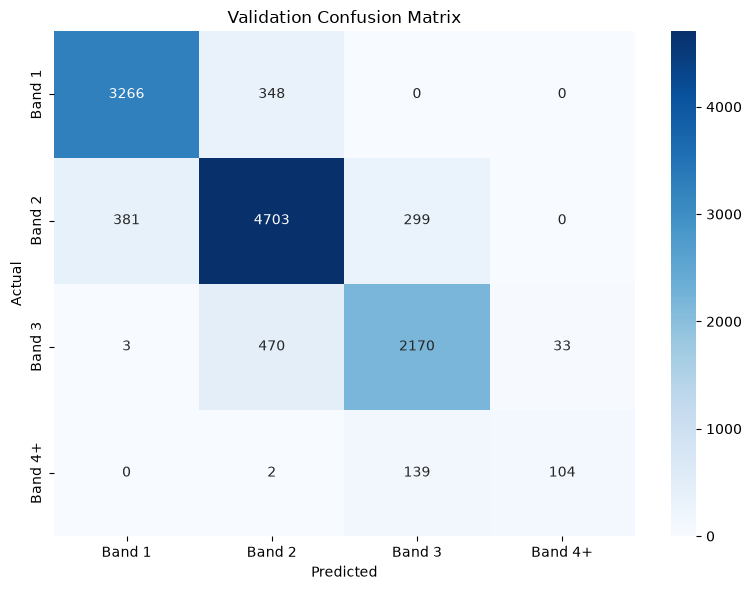

In [27]:
# Make confussion matrix
matrix = confusion_matrix(y_val, best_predictions, labels=classes)

confusion_table = pd.DataFrame(
    matrix,
    index=pd.Index(classes, name="Actual"),
    columns=pd.Index(classes, name="Predicted"),
)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_table, annot=True, fmt="d", cmap="Blues")
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [28]:
# Refit the selected ensemble on all labeled data for final test predictions.
model = VotingClassifier(
    estimators=[
        ("hgb", hgb),
        ("et", et),
    ],
    voting="soft",
    weights=[best_weight, 1 - best_weight],
)

model.fit(X, y)

print("Final ensemble is fitted.")
print("Training rows:", len(X))
print("Test rows:", len(X_test))
print("First five test predictions:", model.predict(X_test.iloc[:5]))

Final ensemble is fitted.
Training rows: 59589
Test rows: 29070
First five test predictions: ['Band 1' 'Band 3' 'Band 2' 'Band 2' 'Band 1']


# Submission

**DILARANG MENGUBAH CODE!!!!!!!!!!!**

**Pastikan memiliki variabel berikut:**
`X_test` (hasil preprocessing dari `df_test`, **jumlah dan urutan barisnya harus sama** dengan `df_test`)

In [29]:
id = df_test['employee_id'].tolist()

y_test = model.predict(X_test)
submission_df = pd.DataFrame({'employee_id': id, 'pay_band': y_test})

assert len(submission_df) == len(df_test), 'Jumlah baris submission harus sama dengan test.csv!'
assert set(submission_df['pay_band']) <= {'Band 1', 'Band 2', 'Band 3', 'Band 4+'}, \
    'Isi pay_band harus label asli: Band 1 / Band 2 / Band 3 / Band 4+'

submission_df.to_csv('submission.csv', index=False)
submission_df.head()

,employee_id,pay_band
0,EMP-196598,Band 1
1,EMP-156920,Band 3
2,EMP-161973,Band 2
3,EMP-195108,Band 2
4,EMP-111307,Band 1
